# Discretized Indices of Convexity

## Useful dependencies

In [76]:
import numpy as np
import numdifftools as nd
import scipy.linalg as la 
import matplotlib.pyplot as plt

## Useful Variables
For lemon: use display_rad=0.33, R=3, r=2.5, display_spacing=0.01

For apple: use display_rad=3.8, same R, r, display_spacing=0.25

For sin(xy): a little more flexible. Just don't force too many calculations.

In [77]:
# Set parameters
R = 3
r = 2.5
f = lambda x: np.sqrt(R**2 - (np.sqrt(x[0]**2 + x[1]**2) - r)**2)
display_rad = 3.8
display_shift = 0
display_spacing = 0.25 # if computations are too slow, make the spacing bigger

## Plot the function to be analyzed

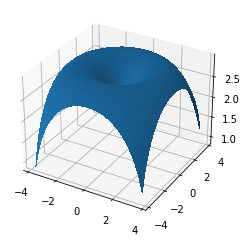

In [78]:
# Plot the function itself
fig = plt.figure()
ax = fig.gca(projection='3d')

# Make data.
Xax = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
Yax = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
X, Y = np.meshgrid(Xax, Yax)
Z = f([X, Y])

# Plot the surface.
surf = ax.plot_surface(X, Y, Z, linewidth=0, antialiased=False)
# Customize the z axis.
# ax.set_zlim(-1, 1)

plt.show()


## Calculate the Hessian and obtain eigenvalues

In [79]:
def hessian(x):
    """
    Calculate the hessian matrix with finite differences
    Parameters:
       - x : ndarray
    Returns:
       an array of shape (x.dim, x.ndim) + x.shape
       where the array[i, j, ...] corresponds to the second derivative x_ij
    """
    x_grad = np.gradient(x) 
    hessian = np.empty((x.ndim, x.ndim) + x.shape, dtype=x.dtype) 
    for k, grad_k in enumerate(x_grad):
        # iterate over dimensions
        # apply gradient again to every component of the first derivative.
        tmp_grad = np.gradient(grad_k) 
        for l, grad_kl in enumerate(tmp_grad):
            hessian[k, l, :, :] = grad_kl
    return hessian

H = hessian(Z)

In [80]:
lamda_1 = np.empty((X.shape[0], X.shape[1]))
lamda_2 = np.empty((X.shape[0], X.shape[1]))
# iterate through the array and calculate the value at each point for lamda_1 and lamda_2, creating two new arrays
for i in range(X.shape[0]):
    for j in range(Y.shape[1]):
        Hlocal = [
            [H[0][0][i][j], H[0][1][i][j]],
            [H[1][0][i][j], H[1][1][i][j]]
        ]
        eigvals, eigvecs = la.eig(Hlocal)
        lamda_1[i][j] = eigvals[0]
        lamda_2[i][j] = eigvals[1]

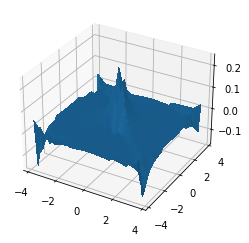

In [81]:
fig1 = plt.figure()
ax1 = fig1.gca(projection='3d')
Xax = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
Yax = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
X, Y = np.meshgrid(Xax, Yax)
surf1 = ax1.plot_surface(X, Y, lamda_1, linewidth=0, antialiased=False)
plt.show()

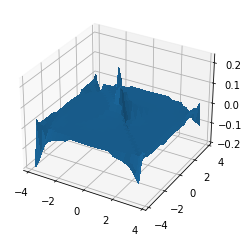

In [82]:
fig2 = plt.figure()
ax2 = fig2.gca(projection='3d')

# Make data.
Xax = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
Y = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
X, Y = np.meshgrid(Xax, Yax)
surf2 = ax2.plot_surface(X, Y, lamda_2, linewidth=0, antialiased=False)

In [83]:
# using these new arrays, calculate the max(lamdma, 0) of each one (plot)
zero = np.zeros(X.shape)

lamda_1_plus = np.maximum(zero, lamda_1)
lamda_2_plus = np.maximum(zero, lamda_2)

lamda_1_minus = np.maximum(zero, -1 * lamda_1)
lamda_2_minus = np.maximum(zero, -1 * lamda_2)

## Using these new arrays, plot indices of convexity. 

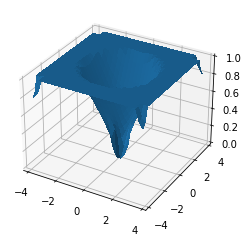

In [84]:
# The index of lack of convexity (normalized)
loc = (lamda_1_minus + lamda_2_minus) / (np.abs(lamda_1) + np.abs(lamda_2))

fig1 = plt.figure()
ax1 = fig1.gca(projection='3d')

Xax = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
Yax = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
X, Y = np.meshgrid(Xax, Yax)
surf1 = ax1.plot_surface(X, Y, loc, linewidth=0, antialiased=False)
plt.show()

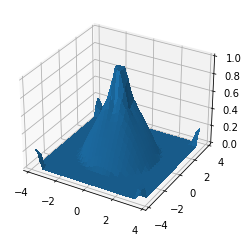

In [85]:
# index of convexity (normalized)
conv = (lamda_1_plus + lamda_2_plus) / (np.abs(lamda_1) + np.abs(lamda_2))

fig1 = plt.figure()
ax1 = fig1.gca(projection='3d')

Xax = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
Yax = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
X, Y = np.meshgrid(Xax, Yax)
surf1 = ax1.plot_surface(X, Y, conv, linewidth=0, antialiased=False)
plt.show()